# Uncertainty-aware neural networks: a calorimeter energy-regression tutorial

We regress the *response* $r = E_\mathrm{meas}/E_\mathrm{true}$ of a toy calorimeter from $(E_\mathrm{true}, \eta)$.

| Ingredient of the toy | Concept it exercises |
|---|---|
| Resolution $\sigma/E = a/\sqrt{E} \oplus b/E \oplus c(\eta)$ | heteroscedastic **aleatoric** uncertainty, with analytic ground truth |
| "Crack" at $\eta \approx 1.5$ (bump in $c$) | localized noise the network must find |
| Low-side tail (leakage), probability growing with $\eta$ | **asymmetric** noise → Gaussian heads miscalibrate, PIT skews |
| No training data for $E_\mathrm{true} \in [120, 200]$ GeV | **epistemic** gap → ensembles/BNNs should widen there |
| A "data" sample with shifted constant term | distribution shift → conformal guarantee breaks |

**Pipeline of the session** (mirrors the lecture): *produce* a predictive distribution → *evaluate* it with proper scores and calibration diagnostics → *repair* the coverage with conformal prediction → re-evaluate.


## 0. Setup

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

rng = np.random.default_rng(42)
torch.manual_seed(42)
plt.rcParams["figure.figsize"] = (11, 3.2)
plt.rcParams["figure.dpi"] = 110

## 1. The toy calorimeter simulator

Gaussian core with relative width
$$\frac{\sigma}{E} = \frac{a}{\sqrt{E}} \oplus \frac{b}{E} \oplus c(\eta),\qquad a = 0.10\ \sqrt{\mathrm{GeV}},\quad b = 0.30\ \mathrm{GeV},$$
where $c(\eta) = 0.01 + 0.05\,e^{-\frac{1}{2}\left(\frac{\eta-1.5}{0.1}\right)^2}$ has a crack at $\eta = 1.5$.
With probability $p_\mathrm{tail}(\eta) = 0.05 + 0.15\,(\eta/2.5)^2$ the response is multiplied by a loss factor $e^{-t}$, $t \sim \mathrm{Exp}(\tau{=}0.08)$: a **low-side tail**.

Because the generator is ours, `sigma_rel_true` is the exact aleatoric ground truth of the Gaussian core — a validation no real dataset allows.

In [2]:
A_STOCH, B_NOISE = 0.10, 0.30  # GeV^0.5, GeV

def constant_term(eta, c_shift=0.0):
    return 0.01 + 0.05 * np.exp(-0.5 * ((eta - 1.5) / 0.10) ** 2) + c_shift

def sigma_rel_true(E, eta, c_shift=0.0):
    c = constant_term(eta, c_shift)
    return np.sqrt(A_STOCH**2 / E + B_NOISE**2 / E**2 + c**2)

def tail_prob(eta):
    return 0.05 + 0.15 * (eta / 2.5) ** 2

def simulate(n, rng, e_range=(5.0, 200.0), train_gap=None, c_shift=0.0):
    '''Toy calorimeter events. train_gap=(lo,hi) removes E_true in that window (epistemic gap);
    c_shift shifts the constant term (distribution shift for Part 12).'''
    E = np.exp(rng.uniform(np.log(e_range[0]), np.log(e_range[1]), n))
    eta = rng.uniform(0.0, 2.5, n)
    if train_gap is not None:
        lo, hi = train_gap
        keep = ~((E > lo) & (E < hi))
        E, eta = E[keep], eta[keep]
        n = E.size
    sig = sigma_rel_true(E, eta, c_shift)
    r = rng.normal(1.0, sig)
    is_tail = rng.random(n) < tail_prob(eta)
    r = r * np.where(is_tail, np.exp(-rng.exponential(0.08, n)), 1.0)
    return dict(E=E, eta=eta, r=r, sigma_core=sig, is_tail=is_tail)

def make_xy(d):
    x = np.stack([np.log(d["E"]), d["eta"]], axis=1).astype(np.float32)
    y = d["r"].astype(np.float32)
    return x, y

class Standardizer:
    def fit(self, x): self.m, self.s = x.mean(0), x.std(0); return self
    def __call__(self, x): return (x - self.m) / self.s

GAP = (120.0, 200.0)
train_d = simulate(50_000, rng, train_gap=GAP)
cal_d   = simulate(10_000, rng, train_gap=GAP)   # conformal calibration: same distribution as training!
test_d  = simulate(20_000, rng)                  # test covers the gap too
x_tr, y_tr = make_xy(train_d); x_cal, y_cal = make_xy(cal_d); x_te, y_te = make_xy(test_d)
std = Standardizer().fit(x_tr)
x_tr, x_cal, x_te = std(x_tr), std(x_cal), std(x_te)
print(f"train {len(y_tr)}  cal {len(y_cal)}  test {len(y_te)}")

train 43125  cal 8550  test 20000


### Look at the data before modelling it

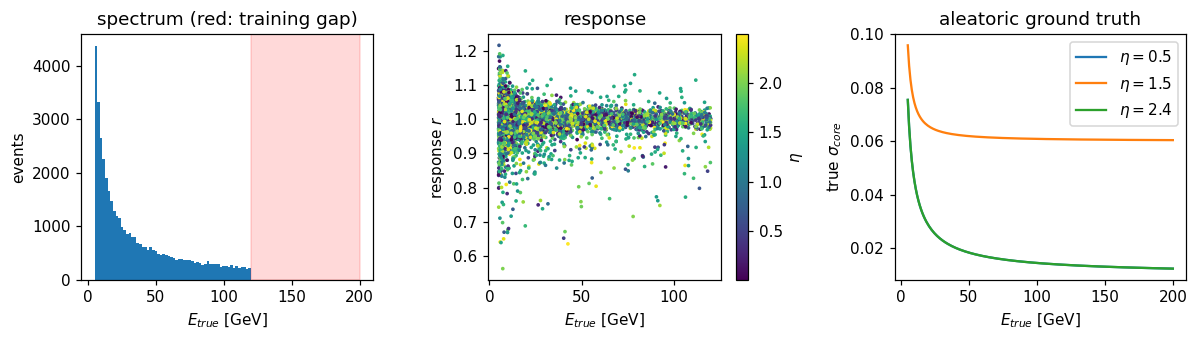

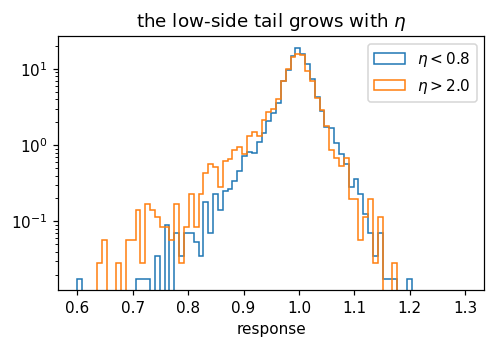

In [3]:
fig, ax = plt.subplots(1, 3)
ax[0].hist(train_d["E"], bins=60); ax[0].axvspan(*GAP, color="r", alpha=0.15)
ax[0].set(xlabel=r"$E_{true}$ [GeV]", ylabel="events", title="spectrum (red: training gap)")
sc = ax[1].scatter(train_d["E"][:4000], train_d["r"][:4000], c=train_d["eta"][:4000], s=2, cmap="viridis")
plt.colorbar(sc, ax=ax[1], label=r"$\eta$")
ax[1].set(xlabel=r"$E_{true}$ [GeV]", ylabel=r"response $r$", title="response")
Egrid = np.linspace(5, 200, 200)
for eta0 in (0.5, 1.5, 2.4):
    ax[2].plot(Egrid, sigma_rel_true(Egrid, np.full_like(Egrid, eta0)), label=fr"$\eta={eta0}$")
ax[2].legend(); ax[2].set(xlabel=r"$E_{true}$ [GeV]", ylabel=r"true $\sigma_{core}$", title="aleatoric ground truth")
plt.tight_layout()

plt.figure(figsize=(5, 3))
lo_eta, hi_eta = test_d["eta"] < 0.8, test_d["eta"] > 2.0
plt.hist(test_d["r"][lo_eta], bins=80, range=(0.6, 1.3), histtype="step", density=True, label=r"$\eta<0.8$")
plt.hist(test_d["r"][hi_eta], bins=80, range=(0.6, 1.3), histtype="step", density=True, label=r"$\eta>2.0$")
plt.yscale("log"); plt.xlabel("response"); plt.legend(); plt.title("the low-side tail grows with $\\eta$");

## 2. The validation toolbox — *before* any model

We will grade every method with the same tools, so we define them first.
All of them consume **predictive samples** `(n_test, S)`, the common currency of every method in this notebook.

- **CRPS** (proper score, headline number): $\mathrm{CRPS} = \mathbb{E}|Y-y| - \tfrac12 \mathbb{E}|Y-Y'|$ — the MAE generalised to distributions.
- **Gaussian NLL** for methods that output $(\mu, \sigma)$.
- **PIT histogram**: $u_i = F_i(y_i)$ must be uniform if calibrated. U-shape = over-confident, hump = under-confident, slope = biased.
- **Coverage & width** of central intervals — remember: either alone can be gamed; together with CRPS they cannot.
- **Reliability curve**: empirical vs nominal coverage across levels.

In [4]:
def pit_values(y, samples):
    return (samples < y[:, None]).mean(axis=1)

def central_coverage(y, samples, level):
    a = (1 - level) / 2
    lo, hi = np.quantile(samples, a, axis=1), np.quantile(samples, 1 - a, axis=1)
    return np.mean((y >= lo) & (y <= hi)), np.mean(hi - lo)

def crps_from_samples(y, samples):
    t1 = np.abs(samples - y[:, None]).mean(axis=1)
    s = np.sort(samples, axis=1); S = samples.shape[1]; k = np.arange(1, S + 1)
    t2 = (2.0 / S**2) * ((2 * k - S - 1) * s).sum(axis=1)   # = E|Y-Y'|
    return float((t1 - 0.5 * t2).mean())

def gauss_nll_score(y, mu, sig):
    return float((0.5 * ((y - mu) / sig) ** 2 + np.log(sig) + 0.5 * np.log(2 * np.pi)).mean())

def plot_pit(y, samples, ax=None, label=""):
    ax = ax or plt.gca()
    ax.hist(pit_values(y, samples), bins=25, density=True, histtype="step", label=label)
    ax.axhline(1, ls="--", c="k", lw=0.8); ax.set(xlabel="PIT", ylabel="density")

def plot_reliability(y, methods, levels=np.linspace(0.1, 0.99, 12)):
    plt.figure(figsize=(4.5, 4))
    for name, s in methods.items():
        plt.plot(levels, [central_coverage(y, s, l)[0] for l in levels], "o-", ms=3, label=name)
    plt.plot([0, 1], [0, 1], "k--", lw=0.8)
    plt.xlabel("nominal coverage"); plt.ylabel("empirical coverage"); plt.legend()

def scoreboard(y, methods, levels=(0.68, 0.95)):
    print(f"{'method':<22}{'CRPS':>9}" + "".join(f"{'cov'+str(int(l*100)):>8}{'width'+str(int(l*100)):>9}" for l in levels))
    for name, s in methods.items():
        row = f"{name:<22}{crps_from_samples(y, s):>9.5f}"
        for l in levels:
            c, w = central_coverage(y, s, l)
            row += f"{c:>8.3f}{w:>9.4f}"
        print(row)

METHODS = {}   # name -> predictive samples on the test set; every part adds one entry

## 3. Baseline: deterministic MLP

Plain MSE training. It has **no uncertainty at all** — we still add it to the scoreboard by treating its prediction as a point mass approximated with a tiny fixed width, to make the failure visible in numbers.

In [5]:
def mlp(n_in, n_out, hidden=64, depth=3, dropout=0.0):
    layers, d = [], n_in
    for _ in range(depth):
        layers += [nn.Linear(d, hidden), nn.ReLU()]
        if dropout > 0: layers += [nn.Dropout(dropout)]
        d = hidden
    return nn.Sequential(*(layers + [nn.Linear(d, n_out)]))

def train(model, loss_fn, x, y, epochs=60, lr=1e-3, batch=512, seed=0, weight_decay=1e-4, shuffle_seed=None):
    torch.manual_seed(seed if shuffle_seed is None else shuffle_seed)
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    x, y = torch.as_tensor(x), torch.as_tensor(y)
    for ep in range(epochs):
        perm = torch.randperm(x.shape[0])
        for i in range(0, x.shape[0], batch):
            idx = perm[i:i + batch]
            opt.zero_grad(); loss_fn(model(x[idx]), y[idx]).backward(); opt.step()
    return model

mse = lambda out, y: ((out.squeeze(-1) - y) ** 2).mean()

det = train(mlp(2, 1), mse, x_tr, y_tr)
with torch.no_grad():
    mu_det = det(torch.as_tensor(x_te)).squeeze(-1).numpy()
METHODS["deterministic (no UQ)"] = mu_det[:, None] + 1e-3 * rng.standard_normal((len(y_te), 200))
print("MSE:", float(((mu_det - y_te) ** 2).mean()))

MSE: 0.002354919444769621


## 4. Aleatoric uncertainty: heteroscedastic Gaussian head 

The network outputs $(\mu(x), \sigma(x))$ trained with the Gaussian NLL — a **proper score**, which is *why* $\sigma$ converges to the true conditional width.
We use the $\beta$-NLL variant (Seitzer et al. 2022) to avoid the classic pathology where badly-fit regions get their $\sigma$ inflated and are never fit.

**Validation unique to a toy**: overlay learned $\sigma(x)$ on the analytic `sigma_rel_true`.

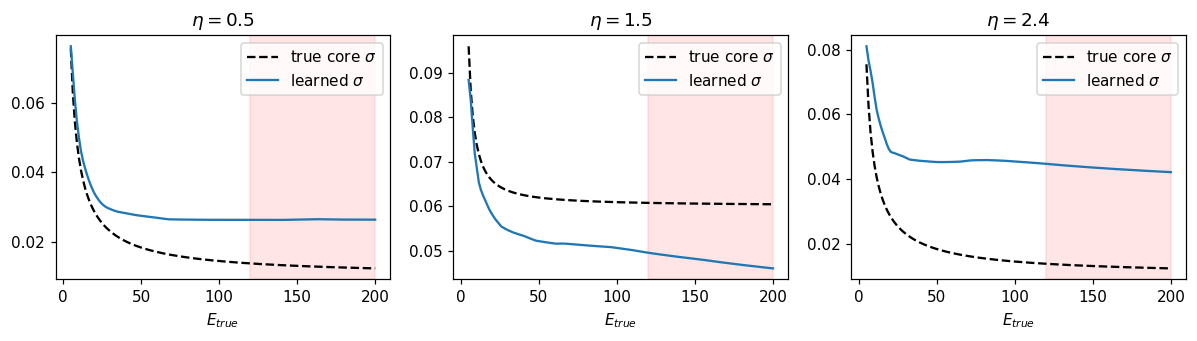

In [6]:
def gauss_nll(out, y, beta=0.5):
    mu, log_s = out[:, 0], out[:, 1]
    sig = nn.functional.softplus(log_s) + 1e-4
    nll = 0.5 * ((y - mu) / sig) ** 2 + torch.log(sig)
    if beta > 0: nll = nll * sig.detach() ** (2 * beta)
    return nll.mean()

def hetero_predict(model, x):
    with torch.no_grad(): out = model(torch.as_tensor(x))
    return out[:, 0].numpy(), nn.functional.softplus(out[:, 1]).numpy() + 1e-4

def gaussian_samples(mu, sig, S=400):
    return mu[:, None] + sig[:, None] * rng.standard_normal((mu.size, S))

het = train(mlp(2, 2), gauss_nll, x_tr, y_tr)
mu_h, sig_h = hetero_predict(het, x_te)
METHODS["heteroscedastic"] = gaussian_samples(mu_h, sig_h)

# learned sigma vs analytic truth
fig, ax = plt.subplots(1, 3)
for a, eta0 in zip(ax, (0.5, 1.5, 2.4)):
    Eg = np.linspace(5, 200, 150)
    xg = std(np.stack([np.log(Eg), np.full_like(Eg, eta0)], 1).astype(np.float32))
    _, sg = hetero_predict(het, xg)
    a.plot(Eg, sigma_rel_true(Eg, np.full_like(Eg, eta0)), "k--", label=r"true core $\sigma$")
    a.plot(Eg, sg, label=r"learned $\sigma$")
    a.axvspan(*GAP, color="r", alpha=0.1); a.set(title=fr"$\eta={eta0}$", xlabel=r"$E_{true}$"); a.legend()
plt.tight_layout()

**Discussion points for the session**
- At high $\eta$ the learned $\sigma$ sits *above* the dashed truth: the Gaussian is inflating to absorb the asymmetric tail it cannot represent. Look at the PIT below: skewed, not uniform.
- Inside the red gap the learned $\sigma$ is an *extrapolation with no data* — and the network is still perfectly confident about it. Aleatoric $\neq$ epistemic.

**EXERCISE**: replace the Gaussian head with (a) a two-component mixture density head or (b) three quantile heads ($\tau = 0.16, 0.5, 0.84$) with pinball loss, and check the PIT straightens out at high $\eta$.

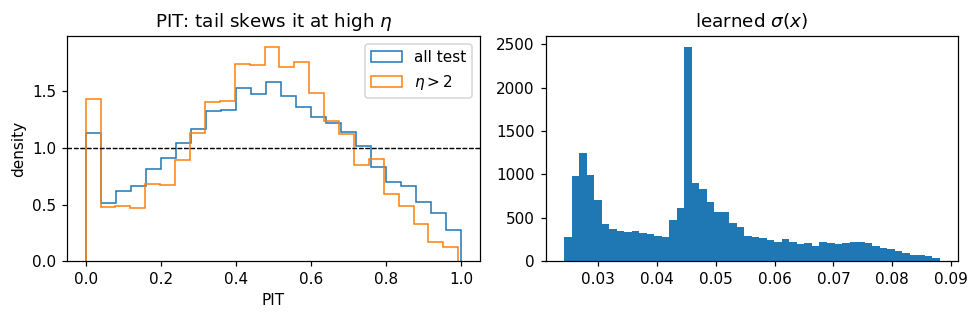

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(9, 3))
plot_pit(y_te, METHODS["heteroscedastic"], ax=ax[0], label="all test")
hi = test_d["eta"] > 2.0
plot_pit(y_te[hi], METHODS["heteroscedastic"][hi], ax=ax[0], label=r"$\eta>2$")
ax[0].legend(); ax[0].set_title("PIT: tail skews it at high $\\eta$")
ax[1].hist(sig_h, bins=50); ax[1].set_title("learned $\\sigma(x)$"); plt.tight_layout()

## 5. Epistemic I: MC dropout

Train with dropout, **keep it on at test time**, average $T$ stochastic passes (Gal & Ghahramani 2016).
Cheapest epistemic signal; remember its known weakness — the spread is set by the dropout rate, not by how much data you have.

**EXERCISE:** implement `mc_dropout_samples(model, x, T)`. 

In [8]:
# === SOLUTION (strip before distributing) ===
drop = train(mlp(2, 2, dropout=0.10), gauss_nll, x_tr, y_tr)

def mc_dropout_samples(model, x, T=100, draws_per_pass=4):
    model.train()                       # dropout active
    outs = []
    with torch.no_grad():
        for _ in range(T):
            out = model(torch.as_tensor(x))
            mu = out[:, 0].numpy(); sig = nn.functional.softplus(out[:, 1]).numpy() + 1e-4
            outs.append(mu[:, None] + sig[:, None] * rng.standard_normal((len(mu), draws_per_pass)))
    model.eval()
    return np.concatenate(outs, axis=1)

METHODS["MC dropout"] = mc_dropout_samples(drop, x_te)

## 6. Epistemic II: deep ensemble

Train $M=5$ heteroscedastic networks from different seeds; the predictive is the equal-weight **mixture** (pool the samples, do *not* average $\mu$ and $\sigma$!).
Epistemic uncertainty = disagreement of the members, exactly the variance decomposition of the lecture:
$\mathrm{Var}[y] = \mathbb{E}_m[\sigma_m^2] + \mathrm{Var}_m[\mu_m]$.

**EXERCISE:** train the ensemble, build pooled samples, then plot $\sqrt{\mathrm{Var}_m[\mu_m]}$ (epistemic) and $\sqrt{\mathbb{E}_m[\sigma_m^2]}$ (aleatoric) vs $E_\mathrm{true}$ — which one lights up in the gap?

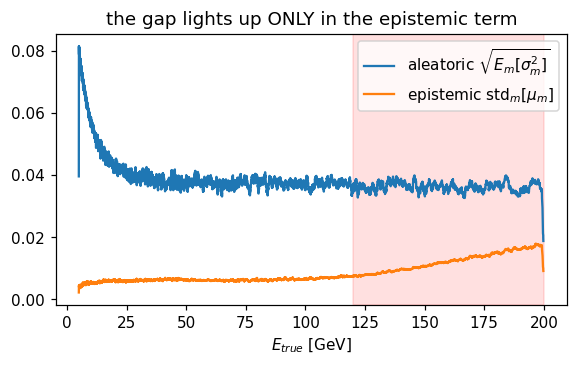

In [9]:
# === SOLUTION ===
M_ENS = 5
members = [train(mlp(2, 2), gauss_nll, x_tr, y_tr, seed=m, shuffle_seed=m) for m in range(M_ENS)]
mus, sigs = zip(*[hetero_predict(m, x_te) for m in members])
mus, sigs = np.stack(mus), np.stack(sigs)              # (M, n_test)
METHODS["deep ensemble"] = np.concatenate([gaussian_samples(mus[m], sigs[m], S=80) for m in range(M_ENS)], axis=1)

epi = mus.std(0); ale = np.sqrt((sigs ** 2).mean(0))
plt.figure(figsize=(6, 3.2))
o = np.argsort(test_d["E"]); k = 40                     # running mean for readability
run = lambda a: np.convolve(a[o], np.ones(k) / k, "same")
plt.plot(test_d["E"][o], run(ale), label="aleatoric $\\sqrt{E_m[\\sigma_m^2]}$")
plt.plot(test_d["E"][o], run(epi), label="epistemic $\\mathrm{std}_m[\\mu_m]$")
plt.axvspan(*GAP, color="r", alpha=0.12); plt.xlabel(r"$E_{true}$ [GeV]"); plt.legend()
plt.title("the gap lights up ONLY in the epistemic term");

## 7. Epistemic III: a variational BNN from scratch (Bayes by Backprop)

Now the real thing: a **distribution over the weights**, learned by variational inference.
Each layer keeps $(\mu_j, \rho_j)$ per weight, $\sigma_j = \mathrm{softplus}(\rho_j)$, and every forward pass draws
$$w = \mu + \sigma \odot \varepsilon,\qquad \varepsilon \sim \mathcal{N}(0, I)$$
(the **reparameterisation trick**: sampling stays differentiable w.r.t. $\mu, \sigma$). Training maximises the ELBO
$$\mathcal{L} = \underbrace{\mathbb{E}_{q}\big[\log p(\mathcal{D} \mid w)\big]}_{\text{fit the data (noisy net)}} - \underbrace{\mathrm{KL}\big(q \,\|\, p(w)\big)}_{\text{stay close to the prior}},$$
which is "loss + weight decay" with one crucial change: the fit term is an expectation over a *noisy* network, so weights the data does not constrain keep a large $\sigma_j$ — the network **learns which of its own parameters it is uncertain about**.

What to expect on the scoreboard: close to the ensemble in CRPS but *under-dispersed* epistemic uncertainty in the gap — the known mean-field pathology (reverse KL is mode-seeking; the factorised family cannot represent weight correlations).

In [10]:
class BayesianLinear(nn.Module):
    """Linear layer with a factorised Gaussian q(w) = N(mu, sigma^2) per weight/bias."""
    def __init__(self, n_in, n_out, prior_std=1.0):
        super().__init__()
        self.w_mu  = nn.Parameter(0.1 * torch.randn(n_out, n_in))
        self.w_rho = nn.Parameter(torch.full((n_out, n_in), -5.0))   # sigma = softplus(rho) ~ 0.007 at init
        self.b_mu  = nn.Parameter(torch.zeros(n_out))
        self.b_rho = nn.Parameter(torch.full((n_out,), -5.0))
        self.prior_std = prior_std

    def sigmas(self):
        return nn.functional.softplus(self.w_rho), nn.functional.softplus(self.b_rho)

    def forward(self, x, sample=True):
        w_s, b_s = self.sigmas()
        if sample:                                   # reparameterisation trick
            w = self.w_mu + w_s * torch.randn_like(w_s)
            b = self.b_mu + b_s * torch.randn_like(b_s)
        else:
            w, b = self.w_mu, self.b_mu
        return nn.functional.linear(x, w, b)

    def kl(self):                                    # KL(N(mu,s^2) || N(0,prior^2)), closed form
        out = 0.0
        for mu, sg in zip((self.w_mu, self.b_mu), self.sigmas()):
            out = out + (torch.log(self.prior_std / sg)
                         + (sg**2 + mu**2) / (2 * self.prior_std**2) - 0.5).sum()
        return out

class BNN(nn.Module):
    def __init__(self, n_in=2, n_out=2, hidden=64, depth=3):
        super().__init__()
        dims = [n_in] + [hidden] * depth + [n_out]
        self.layers = nn.ModuleList(BayesianLinear(a, b) for a, b in zip(dims[:-1], dims[1:]))
    def forward(self, x, sample=True):
        for i, l in enumerate(self.layers):
            x = l(x, sample=sample)
            if i < len(self.layers) - 1: x = torch.relu(x)
        return x
    def kl(self):
        return sum(l.kl() for l in self.layers)

def train_bnn(model, x, y, epochs=60, lr=1e-3, batch=512, kl_scale=1.0):
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    x, y = torch.as_tensor(x), torch.as_tensor(y); N = x.shape[0]
    for ep in range(epochs):
        perm = torch.randperm(N)
        for i in range(0, N, batch):
            idx = perm[i:i + batch]
            opt.zero_grad()
            nll = gauss_nll(model(x[idx]), y[idx], beta=0.0) * N   # sum-scaled likelihood, cf. SGLD
            (nll + kl_scale * model.kl()).backward()               # negative ELBO
            opt.step()
    return model

bnn = train_bnn(BNN(), x_tr, y_tr)

def bnn_samples(model, x, T=100, draws_per_pass=4):
    out = []
    with torch.no_grad():
        for _ in range(T):                                          # each pass = one weight draw
            o = model(torch.as_tensor(x))
            mu = o[:, 0].numpy(); sig = nn.functional.softplus(o[:, 1]).numpy() + 1e-4
            out.append(mu[:, None] + sig[:, None] * rng.standard_normal((len(mu), draws_per_pass)))
    return np.concatenate(out, axis=1)

METHODS["variational BNN (BBB)"] = bnn_samples(bnn, x_te)

### A BNN is a factory of deterministic networks

The clearest way to *see* what a weight posterior means: draw one weight set, **copy it into an ordinary `nn.Sequential`**, and you have one plausible deterministic network; draw again and you have another. MC-averaging stochastic forward passes and averaging over such exported members are the same thing — and the deep ensemble of Part 6, the weight samples collected by SGLD in Part 9, and this factory are three implementations of the *same* predictive integral $\int p(y\mid x, w)\,p(w\mid\mathcal{D})\,dw$, differing only in where the weight samples come from.

**EXERCISES:**
1. Which layers keep uncertain weights? Split the $\sigma_j$ histogram below per layer.
2. Quantify the mean-field under-dispersion: epistemic std in the gap, BBB vs deep ensemble.
3. Study the error dependency on eta and energy.
4. KL annealing: train with `kl_scale` ramping 0→1, or fixed at 0.1 ($\beta$-ELBO); watch the scoreboard and discuss why down-weighting the KL "helps" and what it gives up.
5. Change `prior_std` (0.1, 1, 10) and sample plain nets from the **untrained** BNN: this is the "sample functions from the prior" exercise of the lecture.

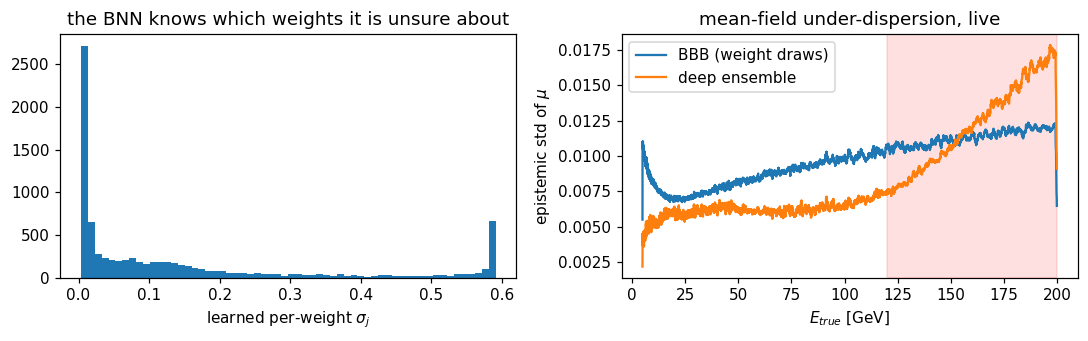

In [11]:
def sample_plain_net(bnn):
    """Draw ONE weight set from q(w) and return an ordinary deterministic MLP carrying it."""
    net = mlp(bnn.layers[0].w_mu.shape[1], bnn.layers[-1].w_mu.shape[0])
    with torch.no_grad():
        for l, m in zip(bnn.layers, [m for m in net if isinstance(m, nn.Linear)]):
            w_s, b_s = l.sigmas()
            m.weight.copy_(l.w_mu + w_s * torch.randn_like(w_s))    # <- forward with replaced weights
            m.bias.copy_(l.b_mu + b_s * torch.randn_like(b_s))
    return net

members = [sample_plain_net(bnn) for _ in range(30)]
mus_f = np.stack([hetero_predict(m, x_te)[0] for m in members])     # (30, n_test)

fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
all_sig = torch.cat([l.sigmas()[0].flatten() for l in bnn.layers]).detach().numpy()
ax[0].hist(all_sig, bins=60)
ax[0].set(xlabel=r"learned per-weight $\sigma_j$", title="the BNN knows which weights it is unsure about")
o = np.argsort(test_d["E"]); k = 40; run = lambda a: np.convolve(a[o], np.ones(k)/k, "same")
ax[1].plot(test_d["E"][o], run(mus_f.std(0)), label="BBB (weight draws)")
ax[1].plot(test_d["E"][o], run(mus.std(0)), label="deep ensemble")   # 'mus' from Part 6
ax[1].axvspan(*GAP, color="r", alpha=0.12); ax[1].legend()
ax[1].set(xlabel=r"$E_{true}$ [GeV]", ylabel=r"epistemic std of $\mu$", title="mean-field under-dispersion, live")
plt.tight_layout()

## 10. Scoreboard + calibration diagnostics — *evaluate*

CRPS ranks the methods (proper: cannot be gamed). Coverage + width show *how* each one fails.
Expected picture: deterministic is sharp and wildly under-covered; the Gaussian head over-covers at 68% while its PIT is skewed (the tail); ensemble/SGLD improve CRPS and the gap; nobody is exactly calibrated → Part 11.

method                     CRPS   cov68  width68   cov95  width95


deterministic (no UQ)   0.03087   0.030   0.0020   0.059   0.0038


heteroscedastic         0.02373   0.806   0.0921   0.956   0.1801


MC dropout              0.02361   0.796   0.0904   0.960   0.1838


deep ensemble           0.02365   0.805   0.0914   0.956   0.1795


variational BNN (BBB)   0.02410   0.830   0.0989   0.961   0.1939


last-layer Laplace      0.02374   0.809   0.0921   0.956   0.1803


cyclical SGLD           0.02380   0.792   0.0906   0.954   0.1777



--- inside the epistemic gap only ---
method                     CRPS   cov68  width68   cov95  width95
deterministic (no UQ)   0.02343   0.038   0.0020   0.081   0.0038
heteroscedastic         0.01869   0.864   0.0713   0.946   0.1394
MC dropout              0.01773   0.870   0.0722   0.958   0.1481
deep ensemble           0.01837   0.873   0.0755   0.950   0.1485


variational BNN (BBB)   0.01867   0.896   0.0841   0.959   0.1650
last-layer Laplace      0.01871   0.865   0.0714   0.945   0.1396
cyclical SGLD           0.01910   0.823   0.0748   0.950   0.1467


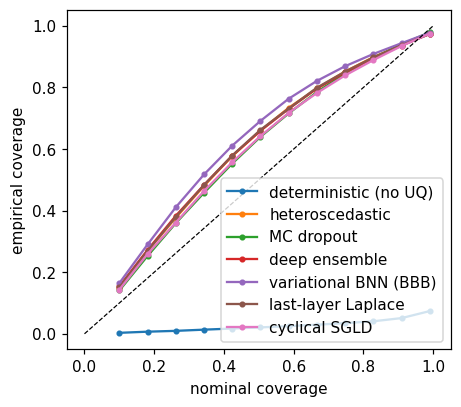

In [14]:
scoreboard(y_te, METHODS)
plot_reliability(y_te, METHODS)
gap_mask = (test_d["E"] > GAP[0]) & (test_d["E"] < GAP[1])
print("\n--- inside the epistemic gap only ---")
scoreboard(y_te[gap_mask], {k: v[gap_mask] for k, v in METHODS.items()})

## 11. Conformal prediction — *repair*

Split conformal on the calibration set (drawn from the **training** distribution — that is the exchangeability requirement).
Score = normalised residual $s = |y - \mu(x)|/\sigma(x)$: the model gives the shape, conformal fixes the scale.
$$\hat q = \text{the } \lceil (n{+}1)(1-\alpha) \rceil / n \text{ empirical quantile of } \{s_i\}, \qquad \mathcal{C}(x) = \mu(x) \pm \hat q\, \sigma(x).$$
Comparing $\hat q$ with the nominal Gaussian quantile ($1.645$ for $\alpha{=}0.1$) is a one-number over/under-confidence diagnostic.

q_hat = 1.389   (Gaussian nominal 1.645)  ->  model is under-confident
conformal coverage on test: 0.904  (target 0.9)


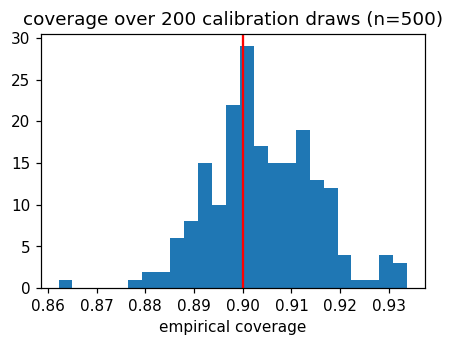

In [15]:
def split_conformal_q(scores_cal, alpha):
    n = scores_cal.size
    k = int(np.ceil((n + 1) * (1 - alpha)))
    return np.sort(scores_cal)[min(k, n) - 1]

alpha = 0.10
mu_c, sig_c = hetero_predict(het, x_cal)
qhat = split_conformal_q(np.abs(y_cal - mu_c) / sig_c, alpha)
print(f"q_hat = {qhat:.3f}   (Gaussian nominal {1.645})  ->  model is {'over' if qhat>1.645 else 'under'}-confident")

lo, hi = mu_h - qhat * sig_h, mu_h + qhat * sig_h
cov = np.mean((y_te >= lo) & (y_te <= hi))
print(f"conformal coverage on test: {cov:.3f}  (target {1-alpha})")

# the theorem, verified: coverage over many calibration/test resamplings ~ Beta
covs = []
for _ in range(200):
    idx = rng.permutation(len(y_cal))[:500]
    q = split_conformal_q(np.abs(y_cal[idx] - mu_c[idx]) / sig_c[idx], alpha)
    covs.append(np.mean((y_te >= mu_h - q * sig_h) & (y_te <= mu_h + q * sig_h)))
plt.figure(figsize=(4.5, 3)); plt.hist(covs, bins=25); plt.axvline(1 - alpha, c="r")
plt.title("coverage over 200 calibration draws (n=500)"); plt.xlabel("empirical coverage");

**EXERCISES:**
1. Coverage *conditionally*: plot empirical coverage in bins of $\eta$. Marginal ≈ 90%, but the crack and high-$\eta$ tail regions deviate — marginal ≠ conditional coverage.
2. Fix it with **CQR**: train quantile heads for $\tau = \alpha/2, 1-\alpha/2$, score $s = \max(\hat q_{lo} - y,\ y - \hat q_{hi})$, conformalise. Asymmetric intervals should absorb the tail.
3. splitting: calibrate separately in 3 $\eta$ bins → exact coverage per bin.

## 12. Distribution shift: when the guarantee breaks

"Data" has a different constant term than the "MC" we calibrated on ($c \to c + 0.02$): exchangeability is gone.

**EXERCISE:** measure the conformal coverage on the shifted sample. Then discuss: which HEP situations are exactly this (sim→data, run-dependent conditions)? 

In [16]:
# === SOLUTION ===
shift_d = simulate(20_000, rng, c_shift=0.02)
x_s, y_s = make_xy(shift_d); x_s = std(x_s)
mu_s, sig_s = hetero_predict(het, x_s)
cov_s = np.mean((y_s >= mu_s - qhat * sig_s) & (y_s <= mu_s + qhat * sig_s))
print(f"coverage on shifted 'data': {cov_s:.3f}   (was {cov:.3f} in-distribution, target {1-alpha})")

coverage on shifted 'data': 0.793   (was 0.904 in-distribution, target 0.9)
